In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully")

Libraries imported successfully


In [60]:
from pathlib import Path

def find_csv(possible_names, keyword):
    current_folder = Path.cwd()

    # Try exact names first
    for name in possible_names:
        file_path = current_folder / name
        if file_path.exists():
            return str(file_path)

    # Try partial search
    for file_path in current_folder.glob("*.csv"):
        name = file_path.name.lower()
        if keyword.lower() in name and not name.startswith("cleaned"):
            return str(file_path)

    raise FileNotFoundError(
        f"CSV file was not found for keyword: {keyword}. "
        f"Put the original CSV file in the same folder as this notebook."
    )

customer_behavior = pd.read_csv(find_csv(
    [
        "E-commerce Customer Behavior - Sheet1.csv",
    ],
    "Customer Behavior"
))

marketing = pd.read_csv(find_csv(
    [
        "marketing_campaign.csv",
    ],
    "marketing_campaign"
), sep="\t")

superstore = pd.read_csv(find_csv(
    [
        "superstore.csv",
    ],
    "superstore"
))

print("Customer Behavior shape:", customer_behavior.shape)
print("Marketing Campaign shape:", marketing.shape)
print("Superstore shape:", superstore.shape)

Customer Behavior shape: (350, 11)
Marketing Campaign shape: (2240, 29)
Superstore shape: (51290, 27)


In [61]:
print("Customer Behavior Dataset")
display(customer_behavior.head())

print("Marketing Campaign Dataset")
display(marketing.head())

print("Superstore Dataset")
display(superstore.head())

Customer Behavior Dataset


,Customer ID,Gender,Age,City,Membership Type,Total Spend,Items Purchased,Average Rating,Discount Applied,Days Since Last Purchase,Satisfaction Level
0,101,Female,29,New York,Gold,1120.20,14,4.6,True,25,Satisfied
1,102,Male,34,Los Angeles,Silver,780.50,11,4.1,False,18,Neutral
2,103,Female,43,Chicago,Bronze,510.75,9,3.4,True,42,Unsatisfied
3,104,Male,30,San Francisco,Gold,1480.30,19,4.7,False,12,Satisfied
4,105,Male,27,Miami,Silver,720.40,13,4.0,True,55,Unsatisfied


Marketing Campaign Dataset


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


Superstore Dataset


,Category,City,Country,Customer.ID,Customer.Name,Discount,Market,记录数,Order.Date,Order.ID,Order.Priority,Product.ID,Product.Name,Profit,Quantity,Region,Row.ID,Sales,Segment,Ship.Date,Ship.Mode,Shipping.Cost,State,Sub.Category,Year,Market2,weeknum
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,2011-01-07 00:00:00.000,CA-2011-130813,High,OFF-PA-10002005,Xerox 225,9.3312,3,West,36624,19,Consumer,2011-01-09 00:00:00.000,Second Class,4.37,California,Paper,2011,North America,2
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,2011-01-21 00:00:00.000,CA-2011-148614,Medium,OFF-PA-10002893,"Wirebound Service Call Books, 5 1/2"" x 4""",9.2928,2,West,37033,19,Consumer,2011-01-26 00:00:00.000,Standard Class,0.94,California,Paper,2011,North America,4
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05 00:00:00.000,CA-2011-118962,Medium,OFF-PA-10000659,"Adams Phone Message Book, Professional, 400 Me...",9.8418,3,West,31468,21,Consumer,2011-08-09 00:00:00.000,Standard Class,1.81,California,Paper,2011,North America,32
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05 00:00:00.000,CA-2011-118962,Medium,OFF-PA-10001144,Xerox 1913,53.2608,2,West,31469,111,Consumer,2011-08-09 00:00:00.000,Standard Class,4.59,California,Paper,2011,North America,32
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,2011-09-29 00:00:00.000,CA-2011-146969,High,OFF-PA-10002105,Xerox 223,3.1104,1,West,32440,6,Consumer,2011-10-03 00:00:00.000,Standard Class,1.32,California,Paper,2011,North America,40


In [62]:
print("Customer Behavior Info")
display(customer_behavior.info())

print("Marketing Campaign Info")
display(marketing.info())

print("Superstore Info")
display(superstore.info())

Customer Behavior Info
<class 'pandas.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer ID               350 non-null    int64  
 1   Gender                    350 non-null    str    
 2   Age                       350 non-null    int64  
 3   City                      350 non-null    str    
 4   Membership Type           350 non-null    str    
 5   Total Spend               350 non-null    float64
 6   Items Purchased           350 non-null    int64  
 7   Average Rating            350 non-null    float64
 8   Discount Applied          350 non-null    bool   
 9   Days Since Last Purchase  350 non-null    int64  
 10  Satisfaction Level        348 non-null    str    
dtypes: bool(1), float64(2), int64(4), str(4)
memory usage: 27.8 KB


None

Marketing Campaign Info
<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240

None

Superstore Info
<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 27 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Category        51290 non-null  str    
 1   City            51290 non-null  str    
 2   Country         51290 non-null  str    
 3   Customer.ID     51290 non-null  str    
 4   Customer.Name   51290 non-null  str    
 5   Discount        51290 non-null  float64
 6   Market          51290 non-null  str    
 7   记录数             51290 non-null  int64  
 8   Order.Date      51290 non-null  str    
 9   Order.ID        51290 non-null  str    
 10  Order.Priority  51290 non-null  str    
 11  Product.ID      51290 non-null  str    
 12  Product.Name    51290 non-null  str    
 13  Profit          51290 non-null  float64
 14  Quantity        51290 non-null  int64  
 15  Region          51290 non-null  str    
 16  Row.ID          51290 non-null  int64  
 17  Sales           51290 non-

None

In [63]:
print("Missing values in Customer Behavior")
display(customer_behavior.isnull().sum())

print("Missing values in Marketing Campaign")
display(marketing.isnull().sum())

print("Missing values in Superstore")
display(superstore.isnull().sum())

Missing values in Customer Behavior


Customer ID                 0
Gender                      0
Age                         0
City                        0
Membership Type             0
Total Spend                 0
Items Purchased             0
Average Rating              0
Discount Applied            0
Days Since Last Purchase    0
Satisfaction Level          2
dtype: int64

Missing values in Marketing Campaign


ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64

Missing values in Superstore


Category          0
City              0
Country           0
Customer.ID       0
Customer.Name     0
Discount          0
Market            0
记录数               0
Order.Date        0
Order.ID          0
Order.Priority    0
Product.ID        0
Product.Name      0
Profit            0
Quantity          0
Region            0
Row.ID            0
Sales             0
Segment           0
Ship.Date         0
Ship.Mode         0
Shipping.Cost     0
State             0
Sub.Category      0
Year              0
Market2           0
weeknum           0
dtype: int64

In [64]:
def clean_column_names(df):
    df = df.copy()
    df.columns = (
        df.columns
        .astype(str)
        .str.strip()
        .str.replace(" ", "_", regex=False)
        .str.replace(".", "_", regex=False)
        .str.replace("-", "_", regex=False)
        .str.replace("/", "_", regex=False)
        .str.lower()
    )
    return df

# In some Superstore files there is an extra empty column. Remove only unnamed columns.
superstore = superstore.loc[:, ~superstore.columns.astype(str).str.lower().str.contains("^unnamed")]
superstore = superstore.drop(columns=[superstore.columns[7]])

customer_behavior = clean_column_names(customer_behavior)
marketing = clean_column_names(marketing)
superstore = clean_column_names(superstore)

print("Cleaned Customer Behavior columns:")
print(customer_behavior.columns.tolist())

print("Cleaned Marketing columns:")
print(marketing.columns.tolist())

print("Cleaned Superstore columns:")
print(superstore.columns.tolist())

Cleaned Customer Behavior columns:
['customer_id', 'gender', 'age', 'city', 'membership_type', 'total_spend', 'items_purchased', 'average_rating', 'discount_applied', 'days_since_last_purchase', 'satisfaction_level']
Cleaned Marketing columns:
['id', 'year_birth', 'education', 'marital_status', 'income', 'kidhome', 'teenhome', 'dt_customer', 'recency', 'mntwines', 'mntfruits', 'mntmeatproducts', 'mntfishproducts', 'mntsweetproducts', 'mntgoldprods', 'numdealspurchases', 'numwebpurchases', 'numcatalogpurchases', 'numstorepurchases', 'numwebvisitsmonth', 'acceptedcmp3', 'acceptedcmp4', 'acceptedcmp5', 'acceptedcmp1', 'acceptedcmp2', 'complain', 'z_costcontact', 'z_revenue', 'response']
Cleaned Superstore columns:
['category', 'city', 'country', 'customer_id', 'customer_name', 'discount', 'market', 'order_date', 'order_id', 'order_priority', 'product_id', 'product_name', 'profit', 'quantity', 'region', 'row_id', 'sales', 'segment', 'ship_date', 'ship_mode', 'shipping_cost', 'state', 'sub_

In [65]:
customer_behavior = customer_behavior.drop_duplicates()

# Replace empty strings with NaN first
customer_behavior = customer_behavior.replace(r"^\s*$", np.nan, regex=True)

# Convert numeric columns
customer_numeric_columns = [
    "customer_id",
    "age",
    "total_spend",
    "items_purchased",
    "average_rating",
    "days_since_last_purchase"
]

for col in customer_numeric_columns:
    if col in customer_behavior.columns:
        customer_behavior[col] = pd.to_numeric(customer_behavior[col], errors="coerce")

# Fill numeric missing values with median
for col in customer_numeric_columns:
    if col in customer_behavior.columns and customer_behavior[col].isna().sum() > 0:
        customer_behavior[col] = customer_behavior[col].fillna(customer_behavior[col].median())

# Clean discount column
customer_behavior["discount_applied"] = customer_behavior["discount_applied"].astype(str).str.strip().str.lower()
customer_behavior["discount_applied"] = customer_behavior["discount_applied"].replace({
    "true": "Yes",
    "false": "No",
    "yes": "Yes",
    "no": "No",
    "1": "Yes",
    "0": "No",
    "nan": "Unknown"
})

# Fill missing satisfaction values
customer_behavior["satisfaction_level"] = customer_behavior["satisfaction_level"].fillna(
    customer_behavior["satisfaction_level"].mode()[0]
)

# Safe calculation: no division by zero and no empty cells
customer_behavior["spend_per_item"] = np.where(
    customer_behavior["items_purchased"] != 0,
    customer_behavior["total_spend"] / customer_behavior["items_purchased"],
    0
)

customer_behavior["age_group"] = pd.cut(
    customer_behavior["age"],
    bins=[0, 25, 35, 45, 60, 100],
    labels=["Under 25", "26-35", "36-45", "46-60", "60+"]
).astype(str)

customer_behavior["age_group"] = customer_behavior["age_group"].replace("nan", "Unknown")

# Fill remaining text missing values
text_cols = customer_behavior.select_dtypes(include=["object"]).columns
for col in text_cols:
    customer_behavior[col] = customer_behavior[col].fillna("Unknown")

customer_behavior = customer_behavior.replace([np.inf, -np.inf], 0)

print("Customer Behavior cleaned successfully")
display(customer_behavior.head())

Customer Behavior cleaned successfully


C:\Users\Аким\AppData\Local\Temp\ipykernel_7912\3425305626.py:58: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_cols = customer_behavior.select_dtypes(include=["object"]).columns


,customer_id,gender,age,city,membership_type,total_spend,items_purchased,average_rating,discount_applied,days_since_last_purchase,satisfaction_level,spend_per_item,age_group
0,101,Female,29,New York,Gold,1120.20,14,4.6,Yes,25,Satisfied,80.014286,26-35
1,102,Male,34,Los Angeles,Silver,780.50,11,4.1,No,18,Neutral,70.954545,26-35
2,103,Female,43,Chicago,Bronze,510.75,9,3.4,Yes,42,Unsatisfied,56.750000,36-45
3,104,Male,30,San Francisco,Gold,1480.30,19,4.7,No,12,Satisfied,77.910526,26-35
4,105,Male,27,Miami,Silver,720.40,13,4.0,Yes,55,Unsatisfied,55.415385,26-35


In [66]:
marketing = marketing.drop_duplicates()

# Replace empty strings with NaN first
marketing = marketing.replace(r"^\s*$", np.nan, regex=True)

# Convert income to numeric
marketing["income"] = pd.to_numeric(marketing["income"], errors="coerce")

# Remove unrealistic income outlier and fill missing income
marketing.loc[marketing["income"] > 200000, "income"] = np.nan
marketing["income"] = marketing["income"].fillna(marketing["income"].median())

# Correct date parsing: marketing_campaign uses day-month-year format
marketing["dt_customer"] = pd.to_datetime(
    marketing["dt_customer"],
    dayfirst=True,
    errors="coerce"
)

# Fill missing dates with median date, so cleaned CSV has no empty date cells
if marketing["dt_customer"].isna().sum() > 0:
    median_date = marketing["dt_customer"].dropna().median()
    marketing["dt_customer"] = marketing["dt_customer"].fillna(median_date)

# Create age and remove unrealistic ages
marketing["age"] = 2026 - marketing["year_birth"]
marketing.loc[marketing["age"] > 100, "age"] = np.nan
marketing.loc[marketing["age"] < 18, "age"] = np.nan
marketing["age"] = marketing["age"].fillna(marketing["age"].median())

# Total spend across product groups
marketing["total_campaign_spend"] = (
    marketing["mntwines"] +
    marketing["mntfruits"] +
    marketing["mntmeatproducts"] +
    marketing["mntfishproducts"] +
    marketing["mntsweetproducts"] +
    marketing["mntgoldprods"]
)

# Total purchases across channels
marketing["total_purchases"] = (
    marketing["numdealspurchases"] +
    marketing["numwebpurchases"] +
    marketing["numcatalogpurchases"] +
    marketing["numstorepurchases"]
)

marketing["children_total"] = marketing["kidhome"] + marketing["teenhome"]

marketing["customer_year"] = marketing["dt_customer"].dt.year.astype(int)
marketing["customer_month"] = marketing["dt_customer"].dt.month.astype(int)

# Correct label: 66+ must be text, not number 66
marketing["age_group"] = pd.cut(
    marketing["age"],
    bins=[17, 25, 35, 45, 55, 65, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65", "66+"]
).astype(str)

marketing["age_group"] = marketing["age_group"].replace("nan", "Unknown")

# Fill numeric missing values
marketing_numeric_cols = marketing.select_dtypes(include=[np.number]).columns
for col in marketing_numeric_cols:
    if marketing[col].isna().sum() > 0:
        marketing[col] = marketing[col].fillna(marketing[col].median())

# Fill text missing values
marketing_text_cols = marketing.select_dtypes(include=["object"]).columns
for col in marketing_text_cols:
    marketing[col] = marketing[col].fillna("Unknown")

marketing = marketing.replace([np.inf, -np.inf], 0)

# Remove rows with invalid marital status
valid_status = ['Married', 'Together', 'Single', 'Divorced', 'Widow']
marketing = marketing[marketing['marital_status'].isin(valid_status)]

print("Marketing Campaign cleaned successfully")
display(marketing.head())

Marketing Campaign cleaned successfully


C:\Users\Аким\AppData\Local\Temp\ipykernel_7912\353625886.py:70: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  marketing_text_cols = marketing.select_dtypes(include=["object"]).columns


,id,year_birth,education,marital_status,income,kidhome,teenhome,dt_customer,recency,mntwines,mntfruits,mntmeatproducts,mntfishproducts,mntsweetproducts,mntgoldprods,numdealspurchases,numwebpurchases,numcatalogpurchases,numstorepurchases,numwebvisitsmonth,acceptedcmp3,acceptedcmp4,acceptedcmp5,acceptedcmp1,acceptedcmp2,complain,z_costcontact,z_revenue,response,age,total_campaign_spend,total_purchases,children_total,customer_year,customer_month,age_group
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1,69.0,1617,25,0,2012,9,66+
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0,72.0,27,6,2,2014,3,66+
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0,61.0,776,21,0,2013,8,56-65
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0,42.0,53,8,1,2014,2,36-45
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0,45.0,422,19,1,2014,1,36-45


In [67]:
superstore = superstore.drop_duplicates()

# Replace empty strings with NaN first
superstore = superstore.replace(r"^\s*$", np.nan, regex=True)

superstore["order_date"] = pd.to_datetime(superstore["order_date"], errors="coerce")
superstore["ship_date"] = pd.to_datetime(superstore["ship_date"], errors="coerce")

# Fill possible missing dates
if superstore["order_date"].isna().sum() > 0:
    superstore["order_date"] = superstore["order_date"].fillna(superstore["order_date"].dropna().median())

if superstore["ship_date"].isna().sum() > 0:
    superstore["ship_date"] = superstore["ship_date"].fillna(superstore["ship_date"].dropna().median())

numeric_columns = ["sales", "profit", "quantity", "discount", "shipping_cost"]

for col in numeric_columns:
    superstore[col] = pd.to_numeric(superstore[col], errors="coerce")
    superstore[col] = superstore[col].fillna(superstore[col].median())

superstore["order_year"] = superstore["order_date"].dt.year.astype(int)
superstore["order_month"] = superstore["order_date"].dt.month.astype(int)
superstore["order_month_name"] = superstore["order_date"].dt.month_name()
superstore["shipping_days"] = (superstore["ship_date"] - superstore["order_date"]).dt.days
superstore["shipping_days"] = superstore["shipping_days"].fillna(superstore["shipping_days"].median())

# Safe profit margin: no infinity if sales = 0
superstore["profit_margin"] = np.where(
    superstore["sales"] != 0,
    superstore["profit"] / superstore["sales"],
    0
)

superstore = superstore.replace([np.inf, -np.inf], 0)

superstore["profit_status"] = np.where(superstore["profit"] >= 0, "Profit", "Loss")

# Fill all remaining text missing values
superstore_text_cols = superstore.select_dtypes(include=["object"]).columns
for col in superstore_text_cols:
    superstore[col] = superstore[col].fillna("Unknown")

# Fill all remaining numeric missing values
superstore_numeric_cols = superstore.select_dtypes(include=[np.number]).columns
for col in superstore_numeric_cols:
    if superstore[col].isna().sum() > 0:
        superstore[col] = superstore[col].fillna(superstore[col].median())

print("Superstore cleaned successfully")
display(superstore.head())

Superstore cleaned successfully


C:\Users\Аким\AppData\Local\Temp\ipykernel_7912\3582229073.py:40: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  superstore_text_cols = superstore.select_dtypes(include=["object"]).columns


,category,city,country,customer_id,customer_name,discount,market,order_date,order_id,order_priority,product_id,product_name,profit,quantity,region,row_id,sales,segment,ship_date,ship_mode,shipping_cost,state,sub_category,year,market2,weeknum,order_year,order_month,order_month_name,shipping_days,profit_margin,profit_status
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,2011-01-07,CA-2011-130813,High,OFF-PA-10002005,Xerox 225,9.3312,3,West,36624,19,Consumer,2011-01-09,Second Class,4.37,California,Paper,2011,North America,2,2011,1,January,2,0.491116,Profit
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,2011-01-21,CA-2011-148614,Medium,OFF-PA-10002893,"Wirebound Service Call Books, 5 1/2"" x 4""",9.2928,2,West,37033,19,Consumer,2011-01-26,Standard Class,0.94,California,Paper,2011,North America,4,2011,1,January,5,0.489095,Profit
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,2011-08-05,CA-2011-118962,Medium,OFF-PA-10000659,"Adams Phone Message Book, Professional, 400 Me...",9.8418,3,West,31468,21,Consumer,2011-08-09,Standard Class,1.81,California,Paper,2011,North America,32,2011,8,August,4,0.468657,Profit
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,2011-08-05,CA-2011-118962,Medium,OFF-PA-10001144,Xerox 1913,53.2608,2,West,31469,111,Consumer,2011-08-09,Standard Class,4.59,California,Paper,2011,North America,32,2011,8,August,4,0.479827,Profit
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,2011-09-29,CA-2011-146969,High,OFF-PA-10002105,Xerox 223,3.1104,1,West,32440,6,Consumer,2011-10-03,Standard Class,1.32,California,Paper,2011,North America,40,2011,9,September,4,0.518400,Profit


In [68]:
print("Customer Behavior final shape:", customer_behavior.shape)
print("Marketing final shape:", marketing.shape)
print("Superstore final shape:", superstore.shape)

print("\nMissing values after cleaning:")

print("\nCustomer Behavior:")
display(customer_behavior.isnull().sum()[customer_behavior.isnull().sum() > 0])

print("\nMarketing:")
display(marketing.isnull().sum()[marketing.isnull().sum() > 0])

print("\nSuperstore:")
display(superstore.isnull().sum()[superstore.isnull().sum() > 0])

print("\nIf nothing is shown under each dataset, then there are no empty cells.")

Customer Behavior final shape: (350, 13)
Marketing final shape: (2233, 36)
Superstore final shape: (51290, 32)

Missing values after cleaning:

Customer Behavior:


Series([], dtype: int64)


Marketing:


Series([], dtype: int64)


Superstore:


Series([], dtype: int64)


If nothing is shown under each dataset, then there are no empty cells.


In [69]:
print("Customer Behavior Summary")
display(customer_behavior.describe())

print("Marketing Campaign Summary")
display(marketing.describe())

print("Superstore Sales Summary")
display(superstore.describe())

Customer Behavior Summary


,customer_id,age,total_spend,items_purchased,average_rating,days_since_last_purchase,spend_per_item
count,350.000000,350.000000,350.000000,350.000000,350.000000,350.000000,350.000000
mean,275.500000,33.597143,845.381714,12.600000,4.019143,26.588571,65.228958
std,101.180532,4.870882,362.058695,4.155984,0.580539,13.440813,8.997629
min,101.000000,26.000000,410.800000,7.000000,3.000000,9.000000,49.525000
25%,188.250000,30.000000,502.000000,9.000000,3.500000,15.000000,57.366667
50%,275.500000,32.500000,775.200000,12.000000,4.100000,23.000000,67.030000
75%,362.750000,37.000000,1160.600000,15.000000,4.500000,38.000000,73.025000
max,450.000000,43.000000,1520.100000,21.000000,4.900000,63.000000,83.592857


Marketing Campaign Summary


,id,year_birth,income,kidhome,teenhome,dt_customer,recency,mntwines,mntfruits,mntmeatproducts,mntfishproducts,mntsweetproducts,mntgoldprods,numdealspurchases,numwebpurchases,numcatalogpurchases,numstorepurchases,numwebvisitsmonth,acceptedcmp3,acceptedcmp4,acceptedcmp5,acceptedcmp1,acceptedcmp2,complain,z_costcontact,z_revenue,response,age,total_campaign_spend,total_purchases,children_total,customer_year,customer_month
count,2233.000000,2233.000000,2233.000000,2233.000000,2233.000000,2233,2233.000000,2233.000000,2233.000000,2233.000000,2233.000000,2233.000000,2233.000000,2233.000000,2233.000000,2233.000000,2233.00000,2233.000000,2233.000000,2233.000000,2233.000000,2233.000000,2233.000000,2233.000000,2233.0,2233.0,2233.000000,2233.000000,2233.000000,2233.000000,2233.000000,2233.000000,2233.000000
mean,5595.398567,1968.790864,51959.071205,0.444245,0.506046,2013-07-10 10:37:08.034035,49.172414,304.033587,26.300940,167.113300,37.445141,27.108374,43.903269,2.321093,4.081505,2.661890,5.79176,5.316167,0.072548,0.074787,0.072548,0.064039,0.013435,0.009404,3.0,11.0,0.148231,57.111509,605.904613,14.856247,0.950291,2013.028213,6.467085
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,2012-07-30 00:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,30.000000,5.000000,0.000000,0.000000,2012.000000,1.000000
25%,2831.000000,1959.000000,35523.000000,0.000000,0.000000,2013-01-17 00:00:00,24.000000,24.000000,1.000000,16.000000,3.000000,1.000000,9.000000,1.000000,2.000000,0.000000,3.00000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,49.000000,68.000000,8.000000,0.000000,2013.000000,3.000000
50%,5462.000000,1970.000000,51373.000000,0.000000,0.000000,2013-07-09 00:00:00,50.000000,173.000000,8.000000,67.000000,12.000000,8.000000,24.000000,2.000000,4.000000,2.000000,5.00000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,56.000000,396.000000,15.000000,1.000000,2013.000000,6.000000
75%,8430.000000,1977.000000,68281.000000,1.000000,1.000000,2013-12-30 00:00:00,74.000000,505.000000,33.000000,232.000000,50.000000,33.000000,56.000000,3.000000,6.000000,4.000000,8.00000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,67.000000,1045.000000,21.000000,1.000000,2013.000000,10.000000
max,11191.000000,1996.000000,162397.000000,2.000000,2.000000,2014-06-29 00:00:00,99.000000,1493.000000,199.000000,1725.000000,259.000000,263.000000,362.000000,15.000000,27.000000,28.000000,13.00000,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000,86.000000,2525.000000,44.000000,3.000000,2014.000000,12.000000
std,3243.198115,11.979248,21422.549513,0.538528,0.544675,NaN,28.962114,336.953019,39.779532,225.870588,54.461569,41.321700,52.009602,1.932181,2.776886,2.921749,3.25473,2.425668,0.259451,0.263107,0.259451,0.244878,0.115153,0.096541,0.0,0.0,0.355408,11.688406,602.697511,7.681929,0.751785,0.683662,3.485623


Superstore Sales Summary


,discount,order_date,profit,quantity,row_id,sales,ship_date,shipping_cost,year,weeknum,order_year,order_month,shipping_days,profit_margin
count,51290.000000,51290,51290.000000,51290.000000,51290.00000,51290.000000,51290,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000
mean,0.142908,2013-05-11 21:26:49.155780,28.610982,3.476545,25645.50000,246.498440,2013-05-15 20:42:42.745174,26.375818,2012.777208,31.287112,2012.777208,7.522636,3.969370,0.047199
min,0.000000,2011-01-01 00:00:00,-6599.978000,1.000000,1.00000,0.000000,2011-01-03 00:00:00,0.002000,2011.000000,1.000000,2011.000000,1.000000,0.000000,-4.727752
25%,0.000000,2012-06-19 00:00:00,0.000000,2.000000,12823.25000,31.000000,2012-06-23 00:00:00,2.610000,2012.000000,20.000000,2012.000000,5.000000,3.000000,0.000000
50%,0.000000,2013-07-08 00:00:00,9.240000,3.000000,25645.50000,85.000000,2013-07-12 00:00:00,7.790000,2013.000000,33.000000,2013.000000,8.000000,4.000000,0.169249
75%,0.200000,2014-05-22 00:00:00,36.810000,5.000000,38467.75000,251.000000,2014-05-26 00:00:00,24.450000,2014.000000,44.000000,2014.000000,10.000000,5.000000,0.333111
max,0.850000,2014-12-31 00:00:00,8399.976000,14.000000,51290.00000,22638.000000,2015-01-07 00:00:00,933.570000,2014.000000,53.000000,2014.000000,12.000000,7.000000,0.582800
std,0.212280,NaN,174.340972,2.278766,14806.29199,487.567175,NaN,57.296810,1.098931,14.429795,1.098931,3.300056,1.729437,0.466845


In [70]:
# What are the sales and profit trends over time?
sales_trend = superstore.groupby("order_year").agg({
    "sales": "sum",
    "profit": "sum",
    "order_id": "nunique"
}).reset_index()

sales_trend = sales_trend.rename(columns={"order_id": "total_orders"})

display(sales_trend)

,order_year,sales,profit,total_orders
0,2011,2259511,248940.81154,4440
1,2012,2677493,307415.27910,5343
2,2013,3405860,406935.23018,6721
3,2014,4300041,504165.97046,8531


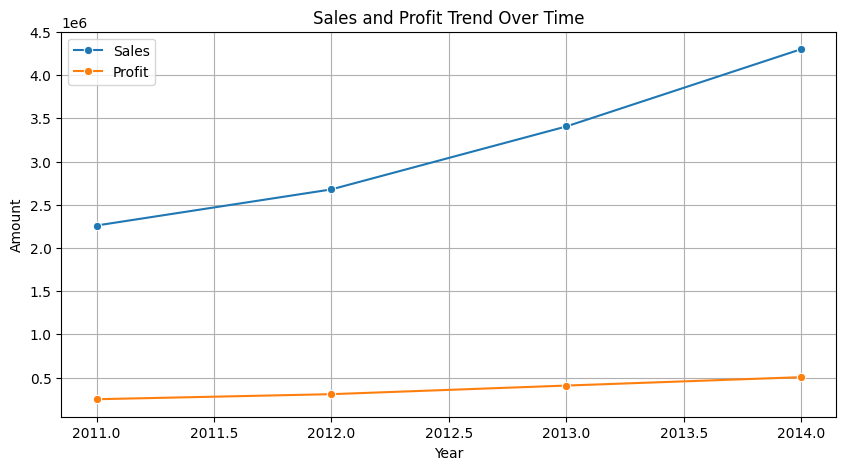

In [71]:
plt.figure(figsize=(10, 5))
sns.lineplot(data=sales_trend, x="order_year", y="sales", marker="o", label="Sales")
sns.lineplot(data=sales_trend, x="order_year", y="profit", marker="o", label="Profit")
plt.title("Sales and Profit Trend Over Time")
plt.xlabel("Year")
plt.ylabel("Amount")
plt.grid(True)
plt.show()

In [72]:
# Which product categories perform best?
category_performance = superstore.groupby("category").agg({
    "sales": "sum",
    "profit": "sum",
    "quantity": "sum",
    "order_id": "nunique"
}).reset_index()

category_performance = category_performance.rename(columns={"order_id": "total_orders"})
category_performance = category_performance.sort_values(by="sales", ascending=False)

display(category_performance)

,category,sales,profit,quantity,total_orders
2,Technology,4744691,663778.73318,35176,8354
0,Furniture,4110884,285204.72380,34954,8195
1,Office Supplies,3787330,518473.83430,108182,19003


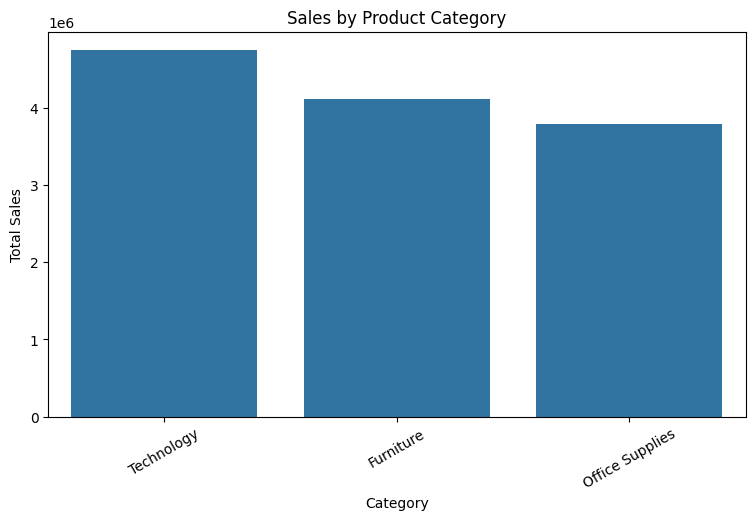

In [73]:
plt.figure(figsize=(9, 5))
sns.barplot(data=category_performance, x="category", y="sales")
plt.title("Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=30)
plt.show()

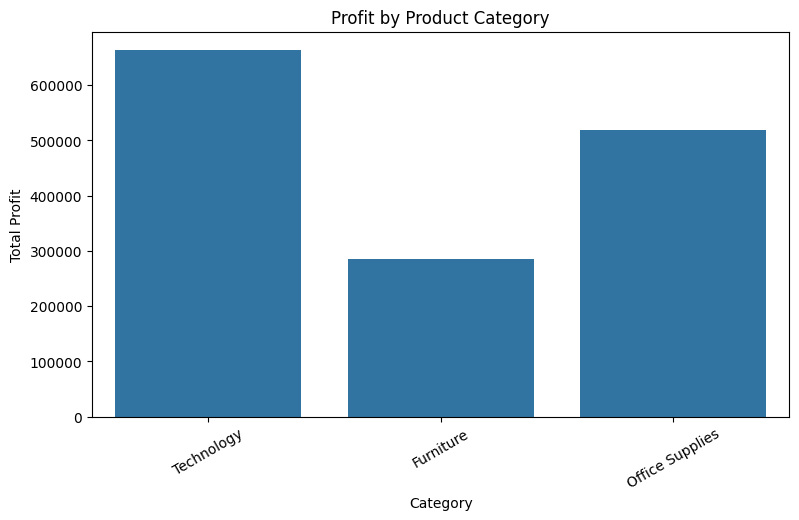

In [74]:
plt.figure(figsize=(9, 5))
sns.barplot(data=category_performance, x="category", y="profit")
plt.title("Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=30)
plt.show()

In [75]:
# Which regions or markets generate the most revenue?
region_performance = superstore.groupby("region").agg({
    "sales": "sum",
    "profit": "sum",
    "quantity": "sum"
}).reset_index()

region_performance = region_performance.sort_values(by="sales", ascending=False)

display(region_performance.head(10))

,region,sales,profit,quantity
3,Central,2822399,311403.98164,41762
10,South,1600960,140355.76618,25206
7,North,1248192,194597.95252,18021
9,Oceania,1100207,120089.11200,12838
11,Southeast Asia,884438,17852.32900,11822
8,North Asia,848349,165578.42100,8851
5,EMEA,806184,43897.97100,11517
0,Africa,783776,88871.63100,10564
4,Central Asia,752839,132480.18700,7715
12,West,725514,108418.44890,12266


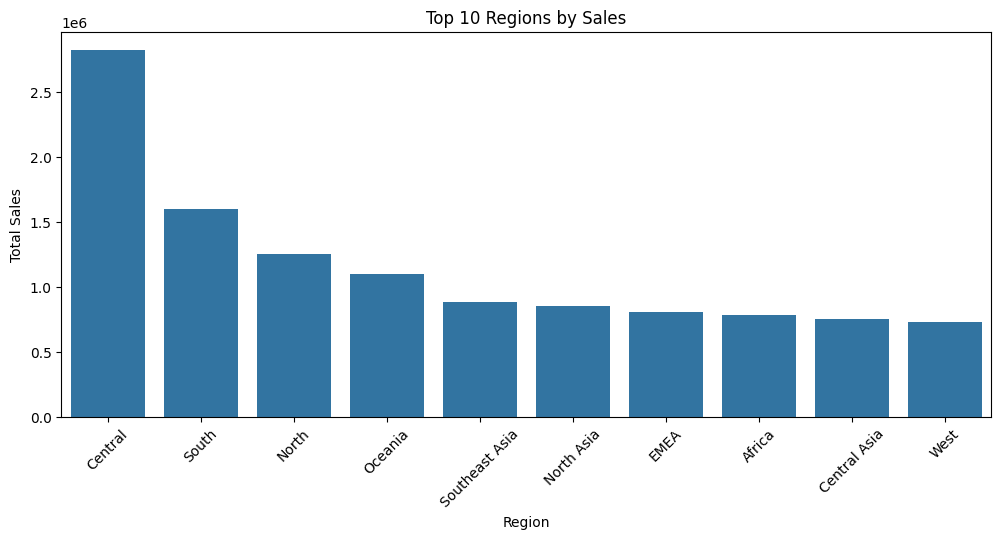

In [76]:
plt.figure(figsize=(12, 5))
sns.barplot(data=region_performance.head(10), x="region", y="sales")
plt.title("Top 10 Regions by Sales")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

In [77]:
# Which membership type spends the most?
membership_analysis = customer_behavior.groupby("membership_type").agg({
    "customer_id": "count",
    "total_spend": "sum",
    "items_purchased": "sum",
    "average_rating": "mean",
    "spend_per_item": "mean"
}).reset_index()

membership_analysis = membership_analysis.rename(columns={"customer_id": "customer_count"})
membership_analysis = membership_analysis.sort_values(by="total_spend", ascending=False)

display(membership_analysis)

,membership_type,customer_count,total_spend,items_purchased,average_rating,spend_per_item
1,Gold,117,153403.9,2061,4.675214,74.775524
2,Silver,117,87566.6,1364,4.051282,64.624438
0,Bronze,116,54913.1,985,3.325000,56.209825


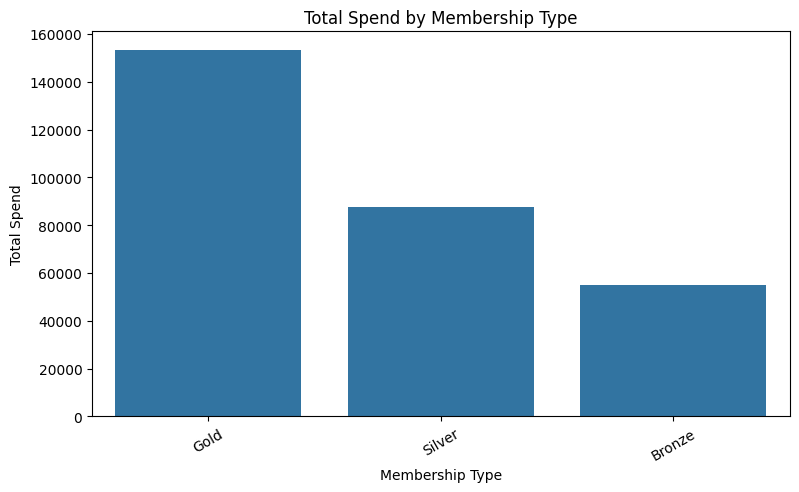

In [78]:
plt.figure(figsize=(9, 5))
sns.barplot(data=membership_analysis, x="membership_type", y="total_spend")
plt.title("Total Spend by Membership Type")
plt.xlabel("Membership Type")
plt.ylabel("Total Spend")
plt.xticks(rotation=30)
plt.show()

In [79]:
satisfaction_analysis = customer_behavior.groupby("satisfaction_level").agg({
    "customer_id": "count",
    "total_spend": "mean",
    "average_rating": "mean",
    "days_since_last_purchase": "mean"
}).reset_index()

satisfaction_analysis = satisfaction_analysis.rename(columns={"customer_id": "customer_count"})

display(satisfaction_analysis)

,satisfaction_level,customer_count,total_spend,average_rating,days_since_last_purchase
0,Neutral,107,616.414019,3.655140,19.289720
1,Satisfied,127,1266.862205,4.624409,17.763780
2,Unsatisfied,116,595.136207,3.692241,42.982759


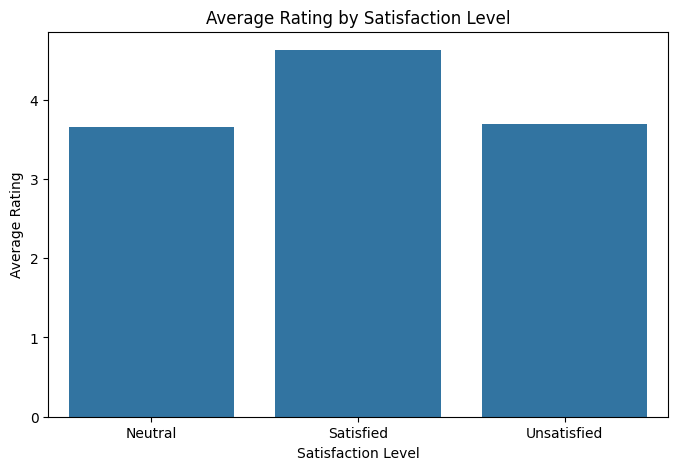

In [80]:
plt.figure(figsize=(8, 5))
sns.barplot(data=satisfaction_analysis, x="satisfaction_level", y="average_rating")
plt.title("Average Rating by Satisfaction Level")
plt.xlabel("Satisfaction Level")
plt.ylabel("Average Rating")
plt.show()

In [81]:
# Which customer segments spend more?
education_analysis = marketing.groupby("education").agg({
    "id": "count",
    "income": "mean",
    "total_campaign_spend": "mean",
    "total_purchases": "mean",
    "response": "mean"
}).reset_index()

education_analysis = education_analysis.rename(columns={
    "id": "customer_count",
    "response": "campaign_response_rate"
})

education_analysis = education_analysis.sort_values(by="total_campaign_spend", ascending=False)

display(education_analysis)

,education,customer_count,income,total_campaign_spend,total_purchases,campaign_response_rate
4,PhD,483,56169.848861,674.728778,15.836439,0.204969
2,Graduation,1125,52153.179556,619.840889,14.987556,0.134222
3,Master,368,52839.529891,610.211957,14.899457,0.154891
0,2n Cycle,203,47688.458128,496.527094,13.802956,0.108374
1,Basic,54,20306.259259,81.796296,7.018519,0.037037


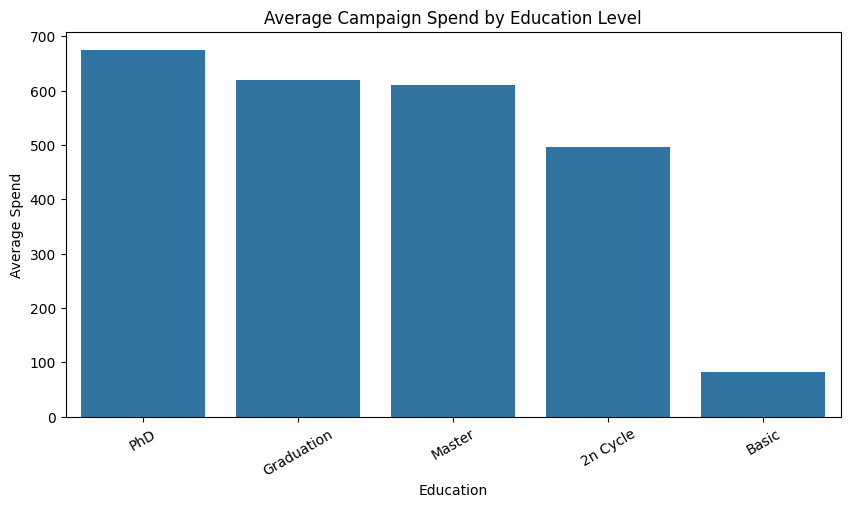

In [82]:
plt.figure(figsize=(10, 5))
sns.barplot(data=education_analysis, x="education", y="total_campaign_spend")
plt.title("Average Campaign Spend by Education Level")
plt.xlabel("Education")
plt.ylabel("Average Spend")
plt.xticks(rotation=30)
plt.show()

In [83]:
response_analysis = marketing.groupby("marital_status").agg({
    "id": "count",
    "response": "mean",
    "income": "mean",
    "total_campaign_spend": "mean"
}).reset_index()

response_analysis = response_analysis.rename(columns={
    "id": "customer_count",
    "response": "response_rate"
})

response_analysis = response_analysis.sort_values(by="response_rate", ascending=False)

display(response_analysis)

,marital_status,customer_count,response_rate,income,total_campaign_spend
4,Widow,77,0.246753,56415.207792,738.818182
2,Single,480,0.220833,51002.431250,606.483333
0,Divorced,232,0.206897,52834.228448,610.629310
1,Married,864,0.113426,51722.127315,590.802083
3,Together,580,0.103448,52162.084483,608.387931


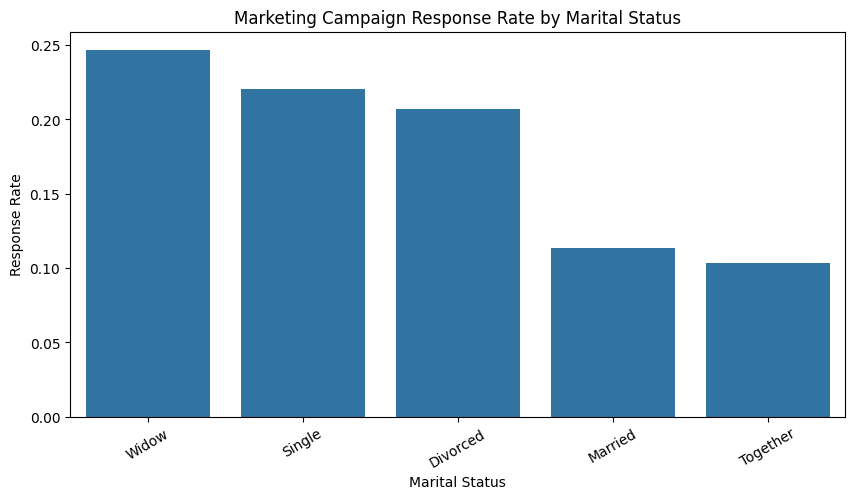

In [84]:
plt.figure(figsize=(10, 5))
sns.barplot(data=response_analysis, x="marital_status", y="response_rate")
plt.title("Marketing Campaign Response Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Response Rate")
plt.xticks(rotation=30)
plt.show()

In [85]:
# Prepare datasets for Power BI
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Profit",
        "Total Orders",
        "Total Quantity Sold",
        "Average Discount",
        "Total Customers in Behavior Dataset",
        "Total Marketing Customers"
    ],
    "Value": [
        superstore["sales"].sum(),
        superstore["profit"].sum(),
        superstore["order_id"].nunique(),
        superstore["quantity"].sum(),
        superstore["discount"].mean(),
        customer_behavior["customer_id"].nunique(),
        marketing["id"].nunique()
    ]
})

display(kpi_summary)

,Metric,Value
0,Total Sales,1.264290e+07
1,Total Profit,1.467457e+06
2,Total Orders,2.503500e+04
3,Total Quantity Sold,1.783120e+05
4,Average Discount,1.429075e-01
5,Total Customers in Behavior Dataset,3.500000e+02
6,Total Marketing Customers,2.233000e+03


In [86]:
# Final safety check before saving: remove any remaining empty cells

def final_no_empty_clean(df):
    df = df.copy()
    df = df.replace(r"^\s*$", np.nan, regex=True)
    df = df.replace([np.inf, -np.inf], 0)

    numeric_cols = df.select_dtypes(include=[np.number]).columns
    for col in numeric_cols:
        if df[col].isna().sum() > 0:
            median_value = df[col].median()
            if pd.isna(median_value):
                median_value = 0
            df[col] = df[col].fillna(median_value)

    datetime_cols = df.select_dtypes(include=["datetime64[ns]"]).columns
    for col in datetime_cols:
        if df[col].isna().sum() > 0:
            median_date = df[col].dropna().median()
            df[col] = df[col].fillna(median_date)

    text_cols = df.select_dtypes(include=["object", "string", "category"]).columns
    for col in text_cols:
        df[col] = df[col].astype(str).replace("nan", "Unknown").fillna("Unknown")

    return df

customer_behavior = final_no_empty_clean(customer_behavior)
marketing = final_no_empty_clean(marketing)
superstore = final_no_empty_clean(superstore)

customer_behavior.to_csv("cleaned_customer_behavior.csv", index=False, encoding="utf-8-sig")
marketing.to_csv("cleaned_marketing_campaign.csv", index=False, encoding="utf-8-sig")
superstore.to_csv("cleaned_superstore_sales.csv", index=False, encoding="utf-8-sig")

print("Only these 3 cleaned files were saved successfully:")
print("1. cleaned_customer_behavior.csv")
print("2. cleaned_marketing_campaign.csv")
print("3. cleaned_superstore_sales.csv")

print("\nFinal check of missing values:")
print("Customer Behavior:", customer_behavior.isnull().sum().sum())
print("Marketing:", marketing.isnull().sum().sum())
print("Superstore:", superstore.isnull().sum().sum())

Only these 3 cleaned files were saved successfully:
1. cleaned_customer_behavior.csv
2. cleaned_marketing_campaign.csv
3. cleaned_superstore_sales.csv

Final check of missing values:
Customer Behavior: 0
Marketing: 0
Superstore: 0
